# Resume Classification with a Vanilla LSTM (Overfitting Baseline)

project pipeline:

0. Config & imports
1. Preprocessing & stratified split
2. Dataset & DataLoaders
3. Model (Vanilla LSTM)
4. Training (deliberate overfitting, no regularization)
5. Evaluation & artifacts


## 0. Config & Imports

In [5]:
import os, re, json, time, random
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader 
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, accuracy_score)

In [6]:
# ───────── CONFIG ─────────
class config:
    SEED = 42

    # Paths (relative to the notebook's working directory)
    _cwd               = os.getcwd()
    BASE_DIR           = os.path.dirname(_cwd) if os.path.basename(_cwd) == "notebooks" else _cwd
    RAW_DATA_PATH      = os.path.join(BASE_DIR, "data", "raw", "resume.csv")
    PROCESSED_DIR      = os.path.join(BASE_DIR, "data", "preprocessed")
    MODELS_DIR         = os.path.join(BASE_DIR, "models")
    
    TRAIN_PATH         = os.path.join(PROCESSED_DIR, "train.csv")
    VAL_PATH           = os.path.join(PROCESSED_DIR, "val.csv")
    TEST_PATH          = os.path.join(PROCESSED_DIR, "test.csv")
    VOCAB_PATH         = os.path.join(PROCESSED_DIR, "vocab.json")
    LABEL_ENCODER_PATH = os.path.join(PROCESSED_DIR, "label_encoder.json")
    
    CHECKPOINT_PATH    = os.path.join(MODELS_DIR, "vanilla_lstm_overfit.pt")
    HISTORY_PATH       = os.path.join(MODELS_DIR, "history.json")

    # Preprocessing
    MAX_LEN     = 400
    VOCAB_SIZE  = 15_000
    TRAIN_RATIO = 0.70
    VAL_RATIO   = 0.15
    TEST_RATIO  = 0.15

    # Model
    EMBEDDING_DIM = 128
    HIDDEN_DIM    = 256
    NUM_LAYERS    = 2
    DROPOUT       = 0.0      # intentionally 0 -> induces overfitting
    NUM_CLASSES   = 24

    # Training
    BATCH_SIZE    = 64
    LEARNING_RATE = 1e-3
    NUM_EPOCHS    = 12
    WEIGHT_DECAY  = 0.0      # intentionally 0 -> induces overfitting

    # Special tokens
    PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
    PAD_IDX, UNK_IDX     = 0, 1
    
    # SAM-RHO value for Sharpness-Aware Minimization (SAM) optimizer
    SAM_RHO = 0.05

os.makedirs(config.PROCESSED_DIR, exist_ok=True)
os.makedirs(config.MODELS_DIR, exist_ok=True)

## 1. Preprocessing & Stratified Split

In [7]:
def clean_text(text: str) -> str:
    """Lowercase, normalise whitespace, strip noisy characters."""
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = text.replace("\u2013", "-").replace("\u2014", "-").replace("\uff0d", "-")
    text = text.replace("\u2022", " ").replace("\u2019", "'").replace("\u00e2", "")
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^a-z0-9 .,'&/+#-]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def tokenize(text: str) -> list[str]:
    return text.split()


def stratified_split(df: pd.DataFrame, seed: int = config.SEED):
    """Per-category split preserving class balance."""
    random.seed(seed)
    train_rows, val_rows, test_rows = [], [], []
    for category, group in df.groupby("Category"):
        group = group.sample(frac=1, random_state=seed).reset_index(drop=True)
        n = len(group)
        n_train = int(n * config.TRAIN_RATIO)
        n_val   = int(n * config.VAL_RATIO)
        train_rows.append(group.iloc[:n_train])
        val_rows.append(group.iloc[n_train:n_train + n_val])
        test_rows.append(group.iloc[n_train + n_val:])
    shuffle = lambda rows: pd.concat(rows).sample(frac=1, random_state=seed).reset_index(drop=True)
    return shuffle(train_rows), shuffle(val_rows), shuffle(test_rows)


def build_vocab(texts: list[str], max_vocab_size: int = config.VOCAB_SIZE) -> dict:
    """token -> index (0=<PAD>, 1=<UNK>, rest by frequency)."""
    counter = Counter()
    for text in texts:
        counter.update(tokenize(text))
    vocab = {config.PAD_TOKEN: config.PAD_IDX, config.UNK_TOKEN: config.UNK_IDX}
    for idx, (token, _) in enumerate(counter.most_common(max_vocab_size - 2), start=2):
        vocab[token] = idx
    return vocab


def build_label_encoder(categories: list[str]) -> dict:
    return {cat: idx for idx, cat in enumerate(sorted(set(categories)))}

In [8]:
df = pd.read_csv(config.RAW_DATA_PATH)
print("Raw shape:", df.shape)

df = df.dropna(subset=["Resume_str"]).reset_index(drop=True)
print("After dropping missing:", df.shape)

df["clean_text"] = df["Resume_str"].apply(clean_text)
df["token_count"] = df["clean_text"].apply(lambda t: len(tokenize(t)))
print(f"Token counts -> min: {df['token_count'].min()}  median: {int(df['token_count'].median())}  max: {df['token_count'].max()}")
print("Resumes with < 20 tokens:", (df["token_count"] < 20).sum())

# Trim to MAX_LEN
df["clean_text"] = df["clean_text"].apply(lambda t: " ".join(tokenize(t)[:config.MAX_LEN]))

train_df, val_df, test_df = stratified_split(df[["ID", "clean_text", "Category"]])
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

for cat in sorted(df["Category"].unique()):
    print(f"  {cat:<25} total={(df['Category']==cat).sum():3d}  "
          f"train={(train_df['Category']==cat).sum():3d}  "
          f"val={(val_df['Category']==cat).sum():2d}  "
          f"test={(test_df['Category']==cat).sum():2d}")

train_df.to_csv(config.TRAIN_PATH, index=False)
val_df.to_csv(config.VAL_PATH, index=False)
test_df.to_csv(config.TEST_PATH, index=False)

# Vocab from TRAIN ONLY
vocab = build_vocab(train_df["clean_text"].tolist())
label_encoder = build_label_encoder(df["Category"].tolist())
print("Vocab size:", len(vocab), "| Classes:", len(label_encoder))

with open(config.VOCAB_PATH, "w", encoding="utf-8") as f:
    json.dump(vocab, f, indent=2)
with open(config.LABEL_ENCODER_PATH, "w", encoding="utf-8") as f:
    json.dump(label_encoder, f, indent=2)

Raw shape: (2484, 4)
After dropping missing: (2484, 4)
Token counts -> min: 0  median: 755  max: 5209
Resumes with < 20 tokens: 1
Train: 1728 | Val: 362 | Test: 394
  ACCOUNTANT                total=118  train= 82  val=17  test=19
  ADVOCATE                  total=118  train= 82  val=17  test=19
  AGRICULTURE               total= 63  train= 44  val= 9  test=10
  APPAREL                   total= 97  train= 67  val=14  test=16
  ARTS                      total=103  train= 72  val=15  test=16
  AUTOMOBILE                total= 36  train= 25  val= 5  test= 6
  AVIATION                  total=117  train= 81  val=17  test=19
  BANKING                   total=115  train= 80  val=17  test=18
  BPO                       total= 22  train= 15  val= 3  test= 4
  BUSINESS-DEVELOPMENT      total=120  train= 84  val=18  test=18
  CHEF                      total=118  train= 82  val=17  test=19
  CONSTRUCTION              total=112  train= 78  val=16  test=18
  CONSULTANT                total=115  trai

## 2. Dataset & DataLoaders

In [9]:
def load_vocab(path=config.VOCAB_PATH) -> dict:
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def load_label_encoder(path=config.LABEL_ENCODER_PATH) -> dict:
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


class ResumeDataset(Dataset):
    """Cleaned text -> padded/truncated token-index tensor; category -> label index."""

    def __init__(self, csv_path, vocab, label_encoder, max_len=config.MAX_LEN):
        self.df = pd.read_csv(csv_path)
        self.df["clean_text"] = self.df["clean_text"].fillna("")
        self.vocab = vocab
        self.label_encoder = label_encoder
        self.max_len = max_len
        self.pad_idx = vocab.get(config.PAD_TOKEN, config.PAD_IDX)
        self.unk_idx = vocab.get(config.UNK_TOKEN, config.UNK_IDX)

    def __len__(self):
        return len(self.df)

    def text_to_indices(self, text: str) -> list[int]:
        indices = [self.vocab.get(tok, self.unk_idx) for tok in text.split()]
        if len(indices) >= self.max_len:
            return indices[: self.max_len]
        return indices + [self.pad_idx] * (self.max_len - len(indices))

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        x = torch.tensor(self.text_to_indices(str(row["clean_text"])), dtype=torch.long)
        y = torch.tensor(self.label_encoder[row["Category"]], dtype=torch.long)
        return x, y


def get_dataloaders(batch_size=config.BATCH_SIZE, num_workers=0):
    vocab = load_vocab()
    label_encoder = load_label_encoder()
    train_ds = ResumeDataset(config.TRAIN_PATH, vocab, label_encoder)
    val_ds   = ResumeDataset(config.VAL_PATH,   vocab, label_encoder)
    test_ds  = ResumeDataset(config.TEST_PATH,  vocab, label_encoder)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=num_workers)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=num_workers)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=num_workers)
    return train_loader, val_loader, test_loader, vocab, label_encoder

In [10]:
train_loader, val_loader, test_loader, vocab, label_encoder = get_dataloaders()
print(f"Vocab size: {len(vocab)} | Classes: {len(label_encoder)}")
print(f"Train: {len(train_loader)} batches ({len(train_loader.dataset)} samples)")
print(f"Val:   {len(val_loader)} batches ({len(val_loader.dataset)} samples)")
print(f"Test:  {len(test_loader)} batches ({len(test_loader.dataset)} samples)")

x_batch, y_batch = next(iter(train_loader))
inv_labels = {v: k for k, v in label_encoder.items()}
print("x:", x_batch.shape, x_batch.dtype, "| y:", y_batch.shape, y_batch.dtype)
print("Sample label:", y_batch[0].item(), "->", inv_labels[y_batch[0].item()])

Vocab size: 15000 | Classes: 24
Train: 27 batches (1728 samples)
Val:   6 batches (362 samples)
Test:  7 batches (394 samples)
x: torch.Size([64, 400]) torch.int64 | y: torch.Size([64]) torch.int64
Sample label: 10 -> CHEF


## 3. Model: Vanilla LSTM Classifier

In [11]:
class VanillaLSTMClassifier(nn.Module):
    """Embedding -> LSTM -> last hidden state -> Linear."""

    def __init__(self, vocab_size=config.VOCAB_SIZE, embedding_dim=config.EMBEDDING_DIM,
                 hidden_dim=config.HIDDEN_DIM, num_layers=config.NUM_LAYERS,
                 num_classes=config.NUM_CLASSES, dropout=config.DROPOUT, pad_idx=config.PAD_IDX):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0, bidirectional=False)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        embedded = self.embedding(x)              # (B, T, E)
        _, (h_n, _) = self.lstm(embedded)         # h_n: (layers, B, H)
        return self.fc(h_n[-1])                   # (B, num_classes)

    def count_parameters(self):
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        return {"total": total, "trainable": trainable}


def build_model(vocab_size=config.VOCAB_SIZE):
    return VanillaLSTMClassifier(vocab_size=vocab_size)

In [12]:
model = build_model(vocab_size=len(vocab))
print(model)
print(model.count_parameters())

with torch.no_grad():
    dummy = torch.randint(0, len(vocab), (config.BATCH_SIZE, config.MAX_LEN))
    assert model(dummy).shape == (config.BATCH_SIZE, config.NUM_CLASSES)
print("Forward-pass check passed.")

VanillaLSTMClassifier(
  (embedding): Embedding(15000, 128, padding_idx=0)
  (lstm): LSTM(128, 256, num_layers=2, batch_first=True)
  (fc): Linear(in_features=256, out_features=24, bias=True)
)
{'total': 2847768, 'trainable': 2847768}
Forward-pass check passed.


## 4. Training (Deliberate Overfitting Experiment)

## 4. Plain LSTM Training (Deliberate Overfitting Experiment)

In [13]:
def set_seed(seed=config.SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for x, y in dataloader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * x.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)
    return running_loss / total, correct / total


def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in dataloader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)
            running_loss += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            total += y.size(0)
    return running_loss / total, correct / total

In [14]:
set_seed(config.SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | Epochs: {config.NUM_EPOCHS} | Batch: {config.BATCH_SIZE} | "
      f"LR: {config.LEARNING_RATE} | Dropout: {config.DROPOUT} | WD: {config.WEIGHT_DECAY}")

model = build_model(vocab_size=len(vocab)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=config.LEARNING_RATE,
                             weight_decay=config.WEIGHT_DECAY)

history = {k: [] for k in ["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "epoch_time_sec"]}
best_val_loss, best_val_epoch = float("inf"), -1
start_total = time.time()

print(f"{'Epoch':<10} | {'Train Loss':<12} | {'Train Acc':<11} | {'Val Loss':<12} | {'Val Acc':<11} | Time")
print("-" * 75)
for epoch in range(1, config.NUM_EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    va_loss, va_acc = evaluate(model, val_loader, criterion, device)
    elapsed = time.time() - t0

    for k, v in zip(history.keys(), [epoch, tr_loss, tr_acc, va_loss, va_acc, elapsed]):
        history[k].append(v)
    if va_loss < best_val_loss:
        best_val_loss, best_val_epoch = va_loss, epoch

    print(f"Epoch [{epoch:02d}/{config.NUM_EPOCHS:02d}] | {tr_loss:10.4f}   | {tr_acc*100:8.2f}%   | "
          f"{va_loss:10.4f}   | {va_acc*100:8.2f}%   | {elapsed:5.1f}s")

print("-" * 75)
print(f"Total training time: {(time.time() - start_total)/60:.2f} min")

Device: cuda | Epochs: 12 | Batch: 64 | LR: 0.001 | Dropout: 0.0 | WD: 0.0
Epoch      | Train Loss   | Train Acc   | Val Loss     | Val Acc     | Time
---------------------------------------------------------------------------
Epoch [01/12] |     3.1645   |     3.94%   |     3.1330   |     6.91%   |   1.7s
Epoch [02/12] |     3.0793   |     9.72%   |     3.1269   |     7.18%   |   1.7s
Epoch [03/12] |     2.8970   |    16.78%   |     3.1419   |     8.29%   |   1.6s
Epoch [04/12] |     2.5701   |    25.17%   |     3.3131   |    11.05%   |   1.5s
Epoch [05/12] |     2.0818   |    41.20%   |     3.4273   |     8.84%   |   1.5s
Epoch [06/12] |     1.5441   |    56.60%   |     3.6815   |     8.84%   |   1.6s
Epoch [07/12] |     1.0835   |    70.14%   |     4.0134   |     8.01%   |   1.6s
Epoch [08/12] |     0.7325   |    81.48%   |     4.4608   |     9.67%   |   1.6s
Epoch [09/12] |     0.4620   |    89.00%   |     4.8302   |     9.12%   |   1.5s
Epoch [10/12] |     0.3528   |    90.86%   |

In [15]:
checkpoint = {
    "epoch": config.NUM_EPOCHS,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "final_train_loss": history["train_loss"][-1],
    "final_train_acc":  history["train_acc"][-1],
    "final_val_loss":   history["val_loss"][-1],
    "final_val_acc":    history["val_acc"][-1],
    "best_val_loss": best_val_loss,
    "best_val_epoch": best_val_epoch,
    "vocab_size": len(vocab),
    "num_classes": len(label_encoder),
    "config": {k: getattr(config, k) for k in
               ["EMBEDDING_DIM","HIDDEN_DIM","NUM_LAYERS","DROPOUT","LEARNING_RATE",
                "WEIGHT_DECAY","BATCH_SIZE","MAX_LEN","SEED"]},
}
torch.save(checkpoint, config.CHECKPOINT_PATH)
with open(config.HISTORY_PATH, "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)

gap = (history["train_acc"][-1] - history["val_acc"][-1]) * 100
print("SUMMARY")
print(f"  Final Train Acc: {history['train_acc'][-1]*100:.2f}%")
print(f"  Final Val Acc:   {history['val_acc'][-1]*100:.2f}%")
print(f"  Generalization gap: {gap:.2f}%")
print(f"  Final Train Loss: {history['train_loss'][-1]:.4f}")
print(f"  Lowest Val Loss:  {best_val_loss:.4f} (epoch {best_val_epoch})")
print(f"  Final Val Loss:   {history['val_loss'][-1]:.4f} (+{history['val_loss'][-1]-best_val_loss:.4f})")

SUMMARY
  Final Train Acc: 91.61%
  Final Val Acc:   10.50%
  Generalization gap: 81.11%
  Final Train Loss: 0.2890
  Lowest Val Loss:  3.1269 (epoch 2)
  Final Val Loss:   5.2512 (+2.1243)


## 5. Evaluation & Artifacts

In [19]:
def plot_training_curves(history: dict, save_path: str, label: str = ""):
    epochs = history["epoch"]
    train_acc = [a * 100 for a in history["train_acc"]]
    val_acc   = [a * 100 for a in history["val_acc"]]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(epochs, history["train_loss"], label="Train Loss", color="#1f77b4", linewidth=2)
    ax1.plot(epochs, history["val_loss"], label="Validation Loss", color="#ff7f0e", linewidth=2, linestyle="--")
    best = int(np.argmin(history["val_loss"]))
    ax1.axvline(x=epochs[best], color="gray", linestyle=":", label=f"Min Val Loss (Ep {epochs[best]})")
    ax1.set_title("Cross-Entropy Loss (Overfitting Divergence)", fontsize=13, fontweight="bold")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.grid(True, alpha=0.3); ax1.legend()

    ax2.plot(epochs, train_acc, label="Train Accuracy", color="#2ca02c", linewidth=2)
    ax2.plot(epochs, val_acc, label="Validation Accuracy", color="#d62728", linewidth=2, linestyle="--")
    ax2.set_title(f"Accuracy (Generalization Gap: {train_acc[-1]-val_acc[-1]:.1f}%)", fontsize=13, fontweight="bold")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy (%)"); ax2.grid(True, alpha=0.3); ax2.legend()
    fig.suptitle(label, fontsize=15, fontweight="bold")
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=200)
    plt.show()
    print(f"[Saved] {save_path}")


def plot_confusion_matrix(cm, labels, save_path, label=""):
    cm_norm = cm.astype("float") / (cm.sum(axis=1)[:, np.newaxis] + 1e-9)
    fig, ax = plt.subplots(figsize=(13, 11))
    im = ax.imshow(cm_norm, interpolation="nearest", cmap="Blues")
    plt.colorbar(im, fraction=0.046, pad=0.04)
    ax.set_xticks(np.arange(len(labels))); ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=90, fontsize=8); ax.set_yticklabels(labels, fontsize=8)
    ax.set_title(f"Normalized Confusion Matrix (Test Set) {label}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted Label"); ax.set_ylabel("True Label")
    plt.tight_layout()
    plt.savefig(save_path, dpi=200)
    plt.show()
    print(f"[Saved] {save_path}")

In [20]:
# Reload the saved checkpoint (mirrors the standalone evaluate script)
class_names = [k for k, _ in sorted(label_encoder.items(), key=lambda kv: kv[1])]

checkpoint = torch.load(config.CHECKPOINT_PATH, map_location=device)
model = build_model(vocab_size=len(vocab)).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(f"Loaded checkpoint trained for {checkpoint['epoch']} epochs. "
      f"Best val loss {checkpoint['best_val_loss']:.4f} at epoch {checkpoint['best_val_epoch']}.")

criterion = nn.CrossEntropyLoss()
total_loss, all_preds, all_targets = 0.0, [], []
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += criterion(logits, y).item() * x.size(0)
        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_targets.extend(y.cpu().numpy())

all_preds, all_targets = np.array(all_preds), np.array(all_targets)
test_loss = total_loss / len(all_targets)
test_acc  = accuracy_score(all_targets, all_preds)
test_f1   = f1_score(all_targets, all_preds, average="macro", zero_division=0)
test_prec = precision_score(all_targets, all_preds, average="macro", zero_division=0)
test_rec  = recall_score(all_targets, all_preds, average="macro", zero_division=0)

print(f"Test Loss: {test_loss:.4f} | Acc: {test_acc*100:.2f}% | Macro F1: {test_f1*100:.2f}% | "
      f"Macro P: {test_prec*100:.2f}% | Macro R: {test_rec*100:.2f}%")
print()
print(classification_report(all_targets, all_preds, labels=range(len(class_names)),
                            target_names=class_names, digits=3, zero_division=0))

Loaded checkpoint trained for 12 epochs. Best val loss 3.1269 at epoch 2.
Test Loss: 5.1464 | Acc: 11.17% | Macro F1: 9.82% | Macro P: 9.96% | Macro R: 10.30%

                        precision    recall  f1-score   support

            ACCOUNTANT      0.118     0.105     0.111        19
              ADVOCATE      0.167     0.158     0.162        19
           AGRICULTURE      0.091     0.100     0.095        10
               APPAREL      0.062     0.062     0.062        16
                  ARTS      0.000     0.000     0.000        16
            AUTOMOBILE      0.000     0.000     0.000         6
              AVIATION      0.105     0.105     0.105        19
               BANKING      0.000     0.000     0.000        18
                   BPO      0.000     0.000     0.000         4
  BUSINESS-DEVELOPMENT      0.062     0.056     0.059        18
                  CHEF      0.312     0.263     0.286        19
          CONSTRUCTION      0.045     0.056     0.050        18
       

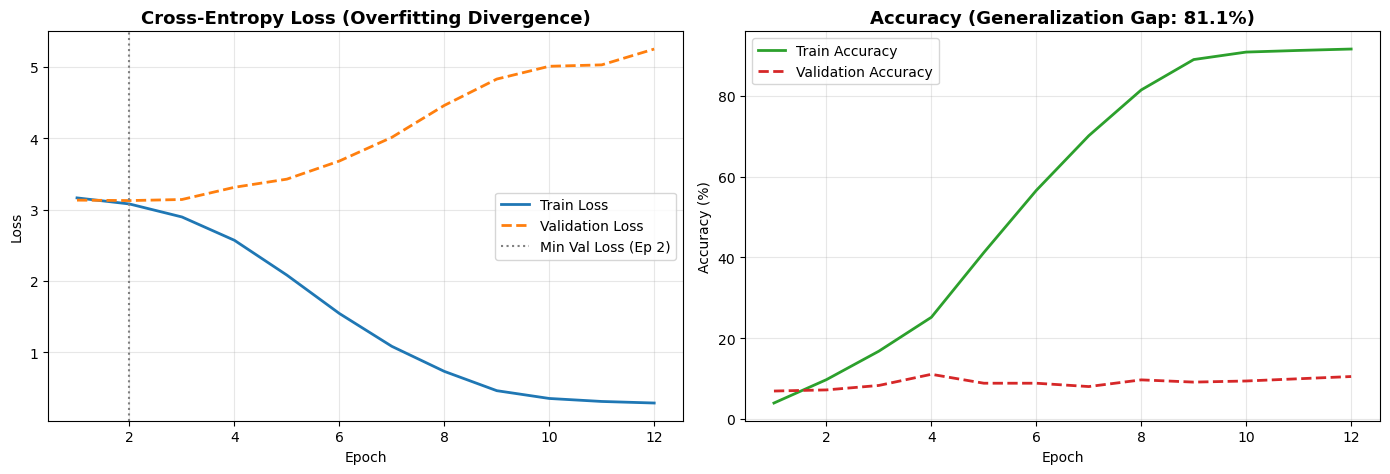

[Saved] d:\GitHub\Documents\nlp-cv\models\overfitting_curves.png


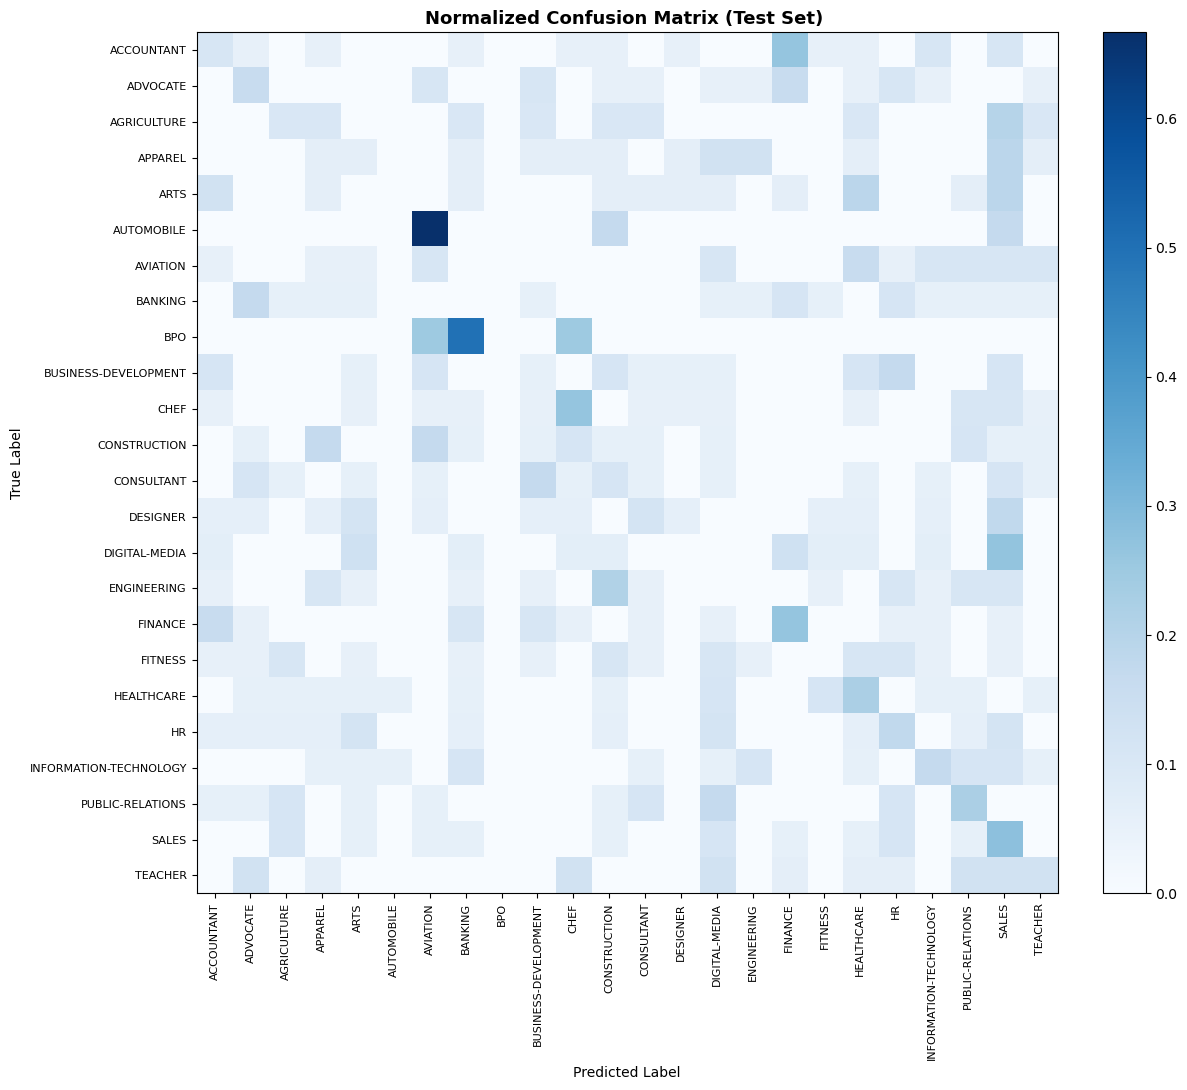

[Saved] d:\GitHub\Documents\nlp-cv\models\confusion_matrix.png
[Saved] d:\GitHub\Documents\nlp-cv\models\baseline_metrics.json


In [21]:
curves_path  = os.path.join(config.MODELS_DIR, "overfitting_curves.png")
cm_path      = os.path.join(config.MODELS_DIR, "confusion_matrix.png")
metrics_path = os.path.join(config.MODELS_DIR, "baseline_metrics.json")

plot_training_curves(history, curves_path)
cm = confusion_matrix(all_targets, all_preds, labels=range(len(class_names)))
plot_confusion_matrix(cm, class_names, cm_path)

summary_metrics = {
    "model_type": "Vanilla LSTM",
    "num_parameters": model.count_parameters()["total"],
    "epochs_trained": checkpoint["epoch"],
    "train_loss": checkpoint["final_train_loss"],
    "train_accuracy": checkpoint["final_train_acc"],
    "val_loss": checkpoint["final_val_loss"],
    "val_accuracy": checkpoint["final_val_acc"],
    "best_val_loss": checkpoint["best_val_loss"],
    "best_val_epoch": checkpoint["best_val_epoch"],
    "test_loss": test_loss,
    "test_accuracy": test_acc,
    "test_macro_f1": test_f1,
    "test_macro_precision": test_prec,
    "test_macro_recall": test_rec,
    "generalization_gap_acc": (checkpoint["final_train_acc"] - checkpoint["final_val_acc"]) * 100,
}
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(summary_metrics, f, indent=2)
print("[Saved]", metrics_path)

## Solution: Pooled LSTM

In [22]:
# ───────── Pooled LSTM ─────────
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
import copy

config.POOL_HIDDEN      = 128
config.POOL_EMB_DROPOUT = 0.2
config.POOL_OUT_DROPOUT = 0.3
config.NUM_EPOCHS_V3    = 30
config.PATIENCE_V3      = 5


class PooledLSTMClassifier(nn.Module):
    """Embedding -> Unidirectional LSTM (padding skipped) ->
    mean + max pooling over all words -> Linear classifier.
    """

    def __init__(self, vocab_size, emb_dim=config.EMBEDDING_DIM,
                 hidden=config.POOL_HIDDEN, num_classes=config.NUM_CLASSES):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, emb_dim, padding_idx=config.PAD_IDX
        )

        self.emb_drop = nn.Dropout(config.POOL_EMB_DROPOUT)

        # Normal LSTM: bidirectional=False by default
        self.lstm = nn.LSTM(
            emb_dim,
            hidden,
            batch_first=True,
            bidirectional=False
        )

        self.out_drop = nn.Dropout(config.POOL_OUT_DROPOUT)

        # Normal LSTM output dimension is hidden
        self.fc = nn.Linear(hidden * 2, num_classes)

    def forward(self, x):
        mask = (x != config.PAD_IDX)
        lengths = mask.sum(1).clamp(min=1)

        emb = self.emb_drop(self.embedding(x))

        # Skip padding tokens during LSTM processing
        packed = pack_padded_sequence(
            emb,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        out, _ = self.lstm(packed)

        out, _ = pad_packed_sequence(
            out,
            batch_first=True,
            total_length=x.size(1)
        )

        # Mean pooling over real tokens
        m = mask.unsqueeze(-1)

        mean_pool = (
            (out * m).sum(1) / lengths.unsqueeze(1)
        )

        # Max pooling over real tokens
        max_pool = out.masked_fill(~m, float('-inf')).max(1).values

        # Concatenate mean and max pooled features
        pooled = torch.cat([mean_pool, max_pool], dim=1)

        # Classification
        return self.fc(self.out_drop(pooled))


# Quick forward-pass check for the Pooled LSTM
with torch.no_grad():
    model = PooledLSTMClassifier(len(vocab)).to(device)
    test_input = torch.randint(
        0, len(vocab), (4, config.MAX_LEN)
    ).to(device)

    output = model(test_input)
    assert output.shape == (4, config.NUM_CLASSES)
    
print(f"Pooled LSTM | Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Output shape: {output.shape}")

Pooled LSTM | Parameters: 2,058,264
Output shape: torch.Size([4, 24])


In [23]:
def train_pooled(tag):
    """Train the Pooled LSTM with early stopping, restore the best epoch,
    and save the checkpoint and training history."""

    set_seed(config.SEED)

    # Pooled LSTM: unidirectional LSTM + mean/max pooling
    model = PooledLSTMClassifier(len(vocab)).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=config.LEARNING_RATE
    )

    history = {
        k: [] for k in [
            "epoch", "train_loss", "train_acc",
            "val_loss", "val_acc", "epoch_time_sec"
        ]
    }

    best_val_loss = float("inf")
    best_epoch = -1
    best_state = None
    bad_epochs = 0

    print(f"\n=== {tag} | Pooled LSTM (mean + max pooling) ===")
    print(
        f"{'Epoch':<10} | {'Train Loss':<12} | {'Train Acc':<11} | "
        f"{'Val Loss':<12} | {'Val Acc':<11} | Time"
    )
    print("-" * 85)

    for epoch in range(1, config.NUM_EPOCHS_V3 + 1):
        t0 = time.time()

        # Training
        tr_loss, tr_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )

        # Validation
        va_loss, va_acc = evaluate(
            model, val_loader, criterion, device
        )

        elapsed = time.time() - t0

        for k, v in zip(
            history.keys(),
            [epoch, tr_loss, tr_acc, va_loss, va_acc, elapsed]
        ):
            history[k].append(v)

        print(
            f"Epoch [{epoch:02d}/{config.NUM_EPOCHS_V3:02d}] | "
            f"{tr_loss:10.4f}   | {tr_acc*100:8.2f}%   | "
            f"{va_loss:10.4f}   | {va_acc*100:8.2f}%   | "
            f"{elapsed:5.1f}s"
        )

        # Early stopping
        if va_loss < best_val_loss:
            best_val_loss = va_loss
            best_epoch = epoch
            bad_epochs = 0
            best_state = copy.deepcopy(model.state_dict())

        else:
            bad_epochs += 1

            if bad_epochs >= config.PATIENCE_V3:
                print(
                    f"Early stopping at epoch {epoch} | "
                    f"best epoch: {best_epoch}"
                )
                break
    # Restore the best model weights
    if best_state is None:
        raise RuntimeError("Training did not produce a valid checkpoint.")
    model.load_state_dict(best_state)
    # Save checkpoint and training history
    paths = run_paths(tag)
    torch.save(
        {
            "model_state_dict": best_state,
            "best_epoch": best_epoch,
            "best_val_loss": best_val_loss,
            "train_acc_at_best": history["train_acc"][best_epoch - 1],
            "val_acc_at_best": history["val_acc"][best_epoch - 1]
        },
        paths["ckpt"]
    )
    with open(paths["history"], "w", encoding="utf-8") as f:
        json.dump(history, f, indent=2)
    print(
        f"\nBest epoch: {best_epoch} | "
        f"Train Acc: {history['train_acc'][best_epoch-1]*100:.2f}% | "
        f"Val Acc: {history['val_acc'][best_epoch-1]*100:.2f}%"
    )
    return model, history, best_epoch

# Train the normal Pooled LSTM only
pooled_lstm, hist_lstm, ep_lstm = train_pooled("pooled_lstm")



=== pooled_lstm | Pooled LSTM (mean + max pooling) ===
Epoch      | Train Loss   | Train Acc   | Val Loss     | Val Acc     | Time
-------------------------------------------------------------------------------------
Epoch [01/30] |     3.1692   |     4.28%   |     3.1225   |     5.52%   |   1.3s
Epoch [02/30] |     3.1247   |     6.66%   |     3.0969   |    16.57%   |   1.2s
Epoch [03/30] |     3.0863   |     9.84%   |     3.0640   |    13.54%   |   1.2s
Epoch [04/30] |     3.0435   |    14.06%   |     3.0139   |    32.04%   |   1.3s
Epoch [05/30] |     2.9690   |    18.92%   |     2.9500   |    16.85%   |   1.2s
Epoch [06/30] |     2.8241   |    24.77%   |     2.7372   |    21.82%   |   1.2s
Epoch [07/30] |     2.6564   |    30.50%   |     2.5568   |    45.30%   |   1.2s
Epoch [08/30] |     2.4790   |    38.72%   |     2.3647   |    45.58%   |   1.3s
Epoch [09/30] |     2.4072   |    39.58%   |     2.3915   |    50.28%   |   1.2s
Epoch [10/30] |     2.2831   |    48.61%   |     2.16

## Evaluation & Artifacts

POOLED LSTM — TEST SET EVALUATION
Test Loss: nan | Accuracy: 73.86% | Macro F1: 66.76% | Macro Precision: 66.88% | Macro Recall: 67.88%

Classification Report:

                        precision    recall  f1-score   support

            ACCOUNTANT      0.905     1.000     0.950        19
              ADVOCATE      0.765     0.684     0.722        19
           AGRICULTURE      0.200     0.100     0.133        10
               APPAREL      0.462     0.375     0.414        16
                  ARTS      0.444     0.250     0.320        16
            AUTOMOBILE      0.000     0.000     0.000         6
              AVIATION      0.458     0.579     0.512        19
               BANKING      0.375     0.667     0.480        18
                   BPO      0.000     0.000     0.000         4
  BUSINESS-DEVELOPMENT      0.850     0.944     0.895        18
                  CHEF      0.895     0.895     0.895        19
          CONSTRUCTION      1.000     0.833     0.909        18
      

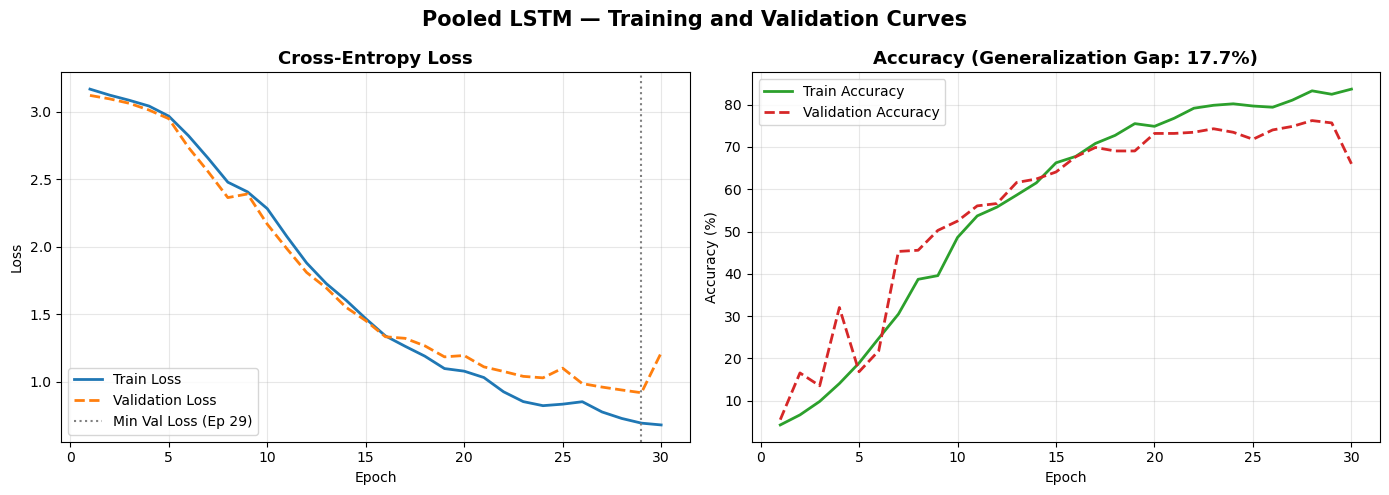

[Saved] d:\GitHub\Documents\nlp-cv\models\pooled_lstm_training_curves.png


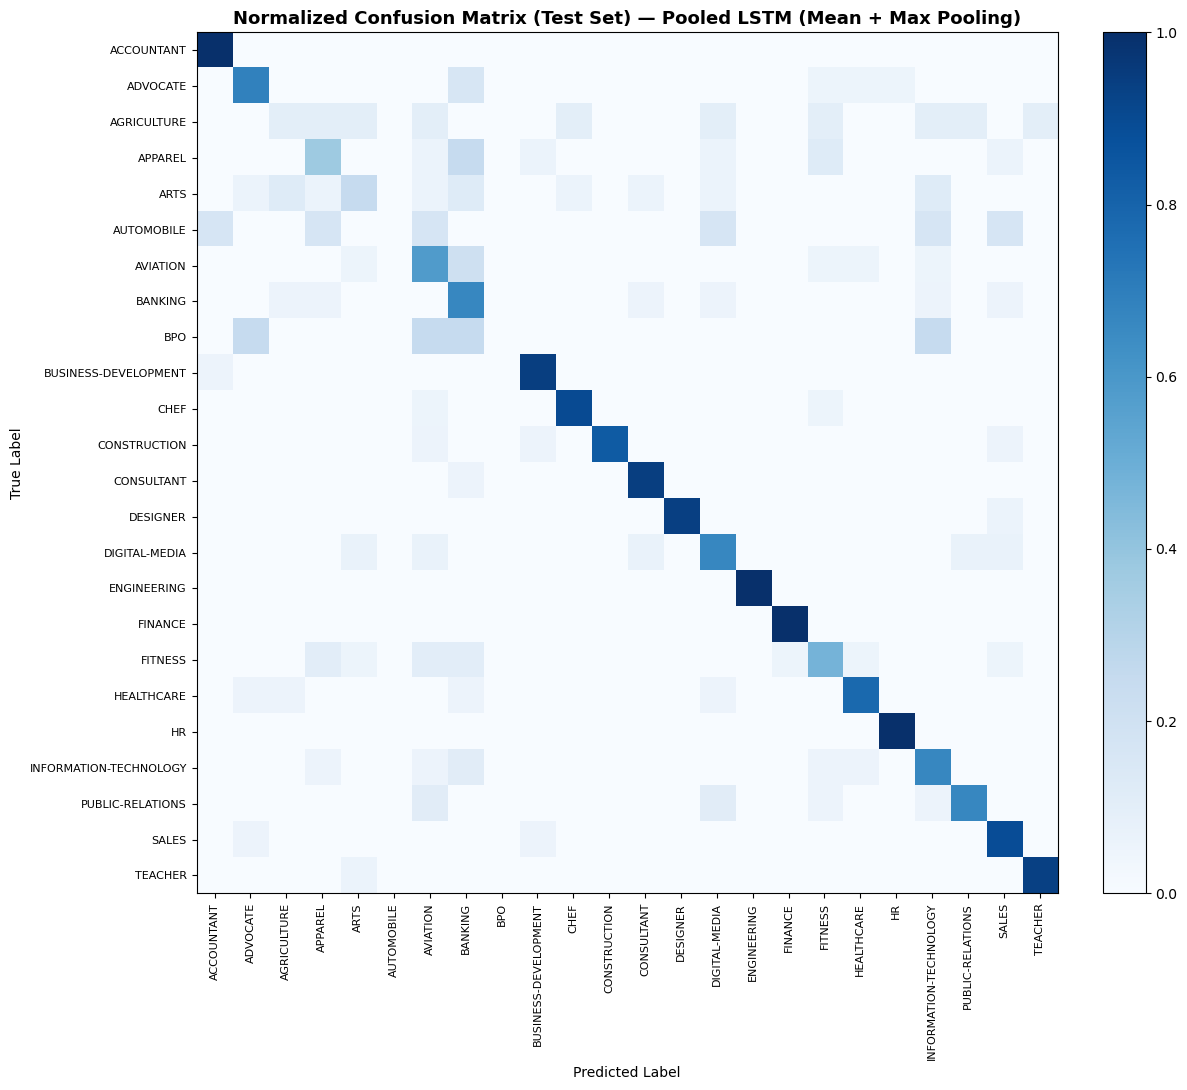

[Saved] d:\GitHub\Documents\nlp-cv\models\pooled_lstm_confusion_matrix.png


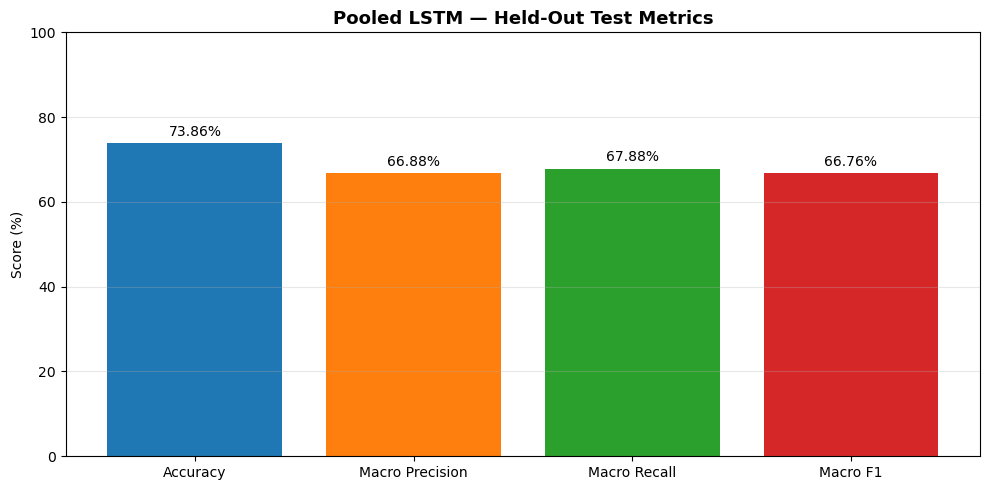

[Saved] d:\GitHub\Documents\nlp-cv\models\pooled_lstm_test_metrics.png
[Saved] d:\GitHub\Documents\nlp-cv\models\pooled_lstm_metrics.json

Pooled LSTM evaluation completed successfully.


In [25]:
# 1. Class labels and evaluation setup
class_names = [
    k for k, v in sorted(label_encoder.items(), key=lambda kv: kv[1])
]

criterion_pooled = nn.CrossEntropyLoss()

pooled_lstm.eval()
pooled_total_loss = 0.0
pooled_preds = []
pooled_targets = []

# 2. Evaluate on the held-out test set
with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)

        logits = pooled_lstm(x)
        loss = criterion_pooled(logits, y)

        pooled_total_loss += loss.item() * x.size(0)

        pooled_preds.extend(logits.argmax(dim=1).cpu().numpy())
        pooled_targets.extend(y.cpu().numpy())

pooled_preds = np.asarray(pooled_preds)
pooled_targets = np.asarray(pooled_targets)

pooled_test_loss = pooled_total_loss / len(pooled_targets)

pooled_test_acc = accuracy_score(pooled_targets, pooled_preds)
pooled_test_f1 = f1_score(
    pooled_targets, pooled_preds, average="macro", zero_division=0
)
pooled_test_prec = precision_score(
    pooled_targets, pooled_preds, average="macro", zero_division=0
)
pooled_test_rec = recall_score(
    pooled_targets, pooled_preds, average="macro", zero_division=0
)

print("=" * 75)
print("POOLED LSTM — TEST SET EVALUATION")
print("=" * 75)

print(
    f"Test Loss: {pooled_test_loss:.4f} | "
    f"Accuracy: {pooled_test_acc * 100:.2f}% | "
    f"Macro F1: {pooled_test_f1 * 100:.2f}% | "
    f"Macro Precision: {pooled_test_prec * 100:.2f}% | "
    f"Macro Recall: {pooled_test_rec * 100:.2f}%"
)

print("\nClassification Report:\n")

print(classification_report(
    pooled_targets,
    pooled_preds,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=3,
    zero_division=0
))


# 3. Output paths
os.makedirs(config.MODELS_DIR, exist_ok=True)

pooled_curves_path = os.path.join(
    config.MODELS_DIR, "pooled_lstm_training_curves.png"
)
pooled_cm_path = os.path.join(
    config.MODELS_DIR, "pooled_lstm_confusion_matrix.png"
)
pooled_metrics_path = os.path.join(
    config.MODELS_DIR, "pooled_lstm_metrics.json"
)
pooled_test_plot_path = os.path.join(
    config.MODELS_DIR, "pooled_lstm_test_metrics.png"
)


# 4. Training curves: loss and accuracy
# Same two-panel layout and colors as the plain LSTM notebook.

epochs = hist_lstm["epoch"]
train_acc_pct = [v * 100 for v in hist_lstm["train_acc"]]
val_acc_pct = [v * 100 for v in hist_lstm["val_acc"]]

best_idx = int(np.argmin(hist_lstm["val_loss"]))
best_epoch = int(ep_lstm)

generalization_gap = train_acc_pct[-1] - val_acc_pct[-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Cross-entropy loss
ax1.plot(
    epochs, hist_lstm["train_loss"],
    label="Train Loss", color="#1f77b4", linewidth=2
)
ax1.plot(
    epochs, hist_lstm["val_loss"],
    label="Validation Loss", color="#ff7f0e",
    linewidth=2, linestyle="--"
)
ax1.axvline(
    x=epochs[best_idx],
    color="gray", linestyle=":",
    label=f"Min Val Loss (Ep {epochs[best_idx]})"
)
ax1.set_title(
    "Cross-Entropy Loss", fontsize=13, fontweight="bold"
)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True, alpha=0.3)
ax1.legend()

# Right: Accuracy
ax2.plot(
    epochs, train_acc_pct,
    label="Train Accuracy", color="#2ca02c", linewidth=2
)
ax2.plot(
    epochs, val_acc_pct,
    label="Validation Accuracy", color="#d62728",
    linewidth=2, linestyle="--"
)
ax2.set_title(
    f"Accuracy (Generalization Gap: {generalization_gap:.1f}%)",
    fontsize=13, fontweight="bold"
)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.grid(True, alpha=0.3)
ax2.legend()

fig.suptitle(
    "Pooled LSTM — Training and Validation Curves",
    fontsize=15, fontweight="bold"
)

plt.tight_layout()
plt.savefig(pooled_curves_path, dpi=200, bbox_inches="tight")
plt.show()

print("[Saved]", pooled_curves_path)


pooled_cm = confusion_matrix(
    pooled_targets,
    pooled_preds,
    labels=np.arange(len(class_names))
)

plot_confusion_matrix(
    pooled_cm,
    class_names,
    pooled_cm_path,
    label="— Pooled LSTM (Mean + Max Pooling)"
)


# 6. Test metrics graph
metric_labels = [
    "Accuracy", "Macro Precision", "Macro Recall", "Macro F1"
]

metric_values = [
    pooled_test_acc * 100,
    pooled_test_prec * 100,
    pooled_test_rec * 100,
    pooled_test_f1 * 100
]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    metric_labels,
    metric_values,
    color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
)

ax.set_title(
    "Pooled LSTM — Held-Out Test Metrics",
    fontsize=13, fontweight="bold"
)
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, metric_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.savefig(pooled_test_plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("[Saved]", pooled_test_plot_path)


# 7. Save evaluation summary
pooled_metrics = {
    "model_type": "Pooled LSTM (Mean + Max Pooling)",
    "num_parameters": sum(
        p.numel() for p in pooled_lstm.parameters()
        if p.requires_grad
    ),
    "epochs_trained": len(hist_lstm["epoch"]),
    "best_val_epoch": best_epoch,
    "best_val_loss": float(hist_lstm["val_loss"][best_idx]),
    "train_acc_at_best": float(hist_lstm["train_acc"][best_idx]),
    "val_acc_at_best": float(hist_lstm["val_acc"][best_idx]),
    "test_loss": float(pooled_test_loss),
    "test_accuracy": float(pooled_test_acc),
    "test_macro_f1": float(pooled_test_f1),
    "test_macro_precision": float(pooled_test_prec),
    "test_macro_recall": float(pooled_test_rec),
    "generalization_gap_acc_pct": float(generalization_gap)
}

with open(pooled_metrics_path, "w", encoding="utf-8") as f:
    json.dump(pooled_metrics, f, indent=2)

print("[Saved]", pooled_metrics_path)

print("\nPooled LSTM evaluation completed successfully.")

## 6. Controlled Comparison: Normal LSTM vs Pooled LSTM

This comparison isolates the **sequence representation** as much as possible:

- **Normal LSTM:** uses the final hidden state of a unidirectional LSTM.
- **Pooled LSTM:** concatenates mean pooling and max pooling over all valid LSTM outputs.

Both models use the same data splits, embedding size, hidden size, dropout rates, optimizer, learning rate, maximum epochs, early-stopping patience, and evaluation metrics. The normal model below is a *matched baseline* trained specifically for this comparison. The earlier `VanillaLSTMClassifier` is deliberately configured as an overfitting experiment, so it should not be the only baseline used to judge whether pooling helps.

The comparison evaluates the two best validation-loss checkpoints on the **same held-out test set**. Run the notebook in order through the Pooled LSTM training cell before running the comparison cell.



=== Matched Normal LSTM | final hidden state ===
Epoch      | Train Loss   | Train Acc   | Val Loss     | Val Acc     | Time
-------------------------------------------------------------------------------------
Epoch [01/30] |     3.1746   |     3.99%   |     3.1664   |     6.63%   |   1.0s
Epoch [02/30] |     3.1202   |     9.38%   |     3.1584   |     6.35%   |   1.0s
Epoch [03/30] |     3.0611   |    14.18%   |     3.1475   |     5.80%   |   1.1s
Epoch [04/30] |     2.9891   |    17.88%   |     3.1502   |     7.18%   |   1.2s
Epoch [05/30] |     2.8795   |    21.76%   |     3.1644   |     4.97%   |   1.2s
Epoch [06/30] |     2.7286   |    25.17%   |     3.1859   |     5.25%   |   1.2s
Epoch [07/30] |     2.5278   |    31.37%   |     3.2357   |     8.56%   |   1.2s
Epoch [08/30] |     2.3399   |    36.23%   |     3.2727   |     6.08%   |   1.0s
Early stopping at epoch 8 | best epoch: 3
[Saved] d:\GitHub\Documents\nlp-cv\models\normal_lstm_matched.pt
[Saved] d:\GitHub\Documents\nlp-c

,Trainable Parameters,Best Epoch,Best Val Loss,Best Val Accuracy (%),Test Loss,Test Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%)
Model,,,,,,,,,
Normal LSTM (final hidden state),"2,055,192",3,3.1475,5.80,3.1416,4.06,2.26,3.57,2.51
Pooled LSTM (mean + max),"2,058,264",29,0.9175,75.69,nan,73.86,66.88,67.88,66.76


[Saved] d:\GitHub\Documents\nlp-cv\models\normal_vs_pooled_lstm_comparison.csv


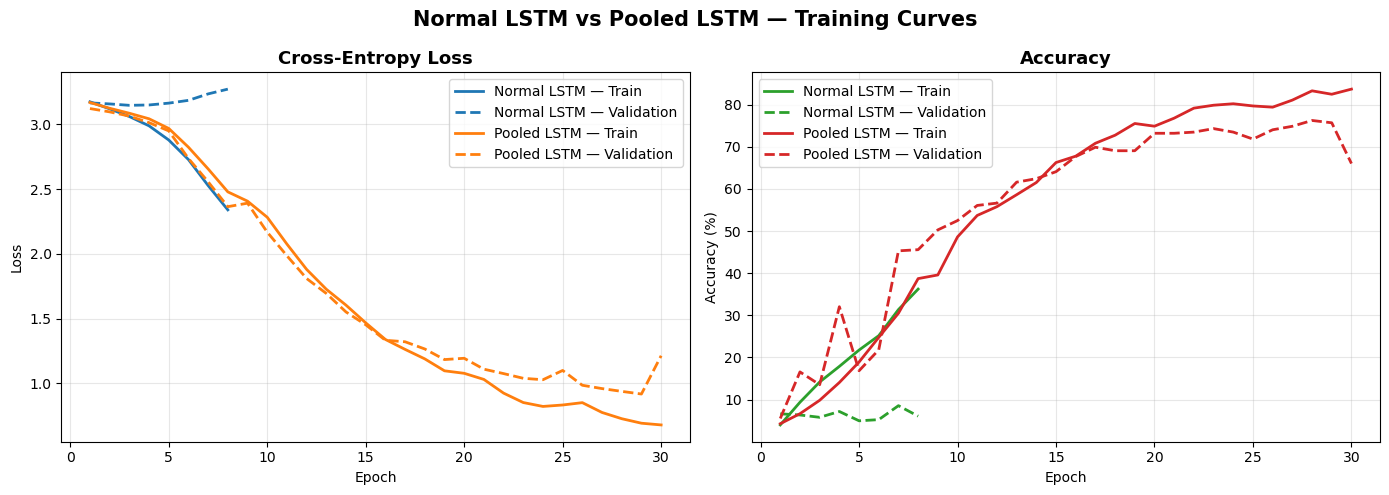

[Saved] d:\GitHub\Documents\nlp-cv\models\normal_vs_pooled_lstm_training_curves.png


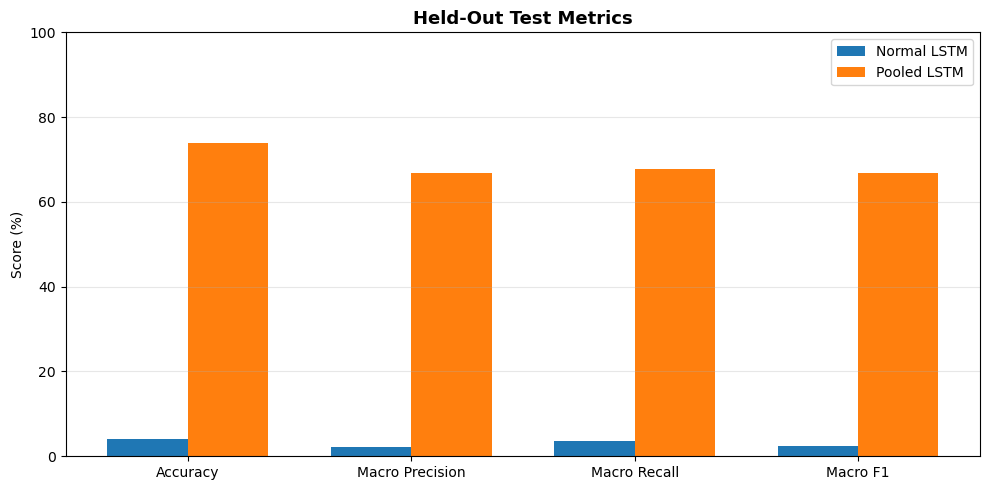

[Saved] d:\GitHub\Documents\nlp-cv\models\normal_vs_pooled_lstm_test_metrics.png

Interpretation: use the held-out test metrics for the final comparison. Higher accuracy/F1 and lower test loss are generally better, but inspect per-class results if some resume categories are underrepresented. The test set must not be used to tune either model.


In [24]:
# ───────── Normal LSTM vs Pooled LSTM: Controlled Comparison ─────────

class FinalStateLSTMClassifier(nn.Module):
    """Matched normal LSTM: embedding -> packed LSTM -> final hidden state -> classifier."""

    def __init__(self, vocab_size, emb_dim=config.EMBEDDING_DIM,
                 hidden=config.POOL_HIDDEN, num_classes=config.NUM_CLASSES):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=config.PAD_IDX)
        self.emb_drop = nn.Dropout(config.POOL_EMB_DROPOUT)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=False)
        self.out_drop = nn.Dropout(config.POOL_OUT_DROPOUT)
        self.fc = nn.Linear(hidden, num_classes)

    def forward(self, x):
        mask = (x != config.PAD_IDX)
        lengths = mask.sum(1).clamp(min=1)
        emb = self.emb_drop(self.embedding(x))
        packed = pack_padded_sequence(
            emb, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (h_n, _) = self.lstm(packed)
        return self.fc(self.out_drop(h_n[-1]))


# Train the matched normal LSTM using the same settings as the Pooled LSTM.
set_seed(config.SEED)
normal_lstm_matched = FinalStateLSTMClassifier(len(vocab)).to(device)
criterion_compare = nn.CrossEntropyLoss()
optimizer_compare = torch.optim.Adam(
    normal_lstm_matched.parameters(), lr=config.LEARNING_RATE
)

hist_normal_matched = {
    k: [] for k in [
        "epoch", "train_loss", "train_acc", "val_loss", "val_acc", "epoch_time_sec"
    ]
}
best_normal_val_loss = float("inf")
best_normal_epoch = -1
best_normal_state = None
normal_bad_epochs = 0

print("\n=== Matched Normal LSTM | final hidden state ===")
print(
    f"{'Epoch':<10} | {'Train Loss':<12} | {'Train Acc':<11} | "
    f"{'Val Loss':<12} | {'Val Acc':<11} | Time"
)
print("-" * 85)

for epoch in range(1, config.NUM_EPOCHS_V3 + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(
        normal_lstm_matched, train_loader, criterion_compare, optimizer_compare, device
    )
    va_loss, va_acc = evaluate(
        normal_lstm_matched, val_loader, criterion_compare, device
    )
    elapsed = time.time() - t0

    for k, v in zip(
        hist_normal_matched.keys(),
        [epoch, tr_loss, tr_acc, va_loss, va_acc, elapsed]
    ):
        hist_normal_matched[k].append(v)

    print(
        f"Epoch [{epoch:02d}/{config.NUM_EPOCHS_V3:02d}] | "
        f"{tr_loss:10.4f}   | {tr_acc*100:8.2f}%   | "
        f"{va_loss:10.4f}   | {va_acc*100:8.2f}%   | {elapsed:5.1f}s"
    )

    if va_loss < best_normal_val_loss:
        best_normal_val_loss = va_loss
        best_normal_epoch = epoch
        best_normal_state = copy.deepcopy(normal_lstm_matched.state_dict())
        normal_bad_epochs = 0
    else:
        normal_bad_epochs += 1
        if normal_bad_epochs >= config.PATIENCE_V3:
            print(
                f"Early stopping at epoch {epoch} | best epoch: {best_normal_epoch}"
            )
            break

if best_normal_state is None:
    raise RuntimeError("Matched normal LSTM training did not produce a valid checkpoint.")

normal_lstm_matched.load_state_dict(best_normal_state)
normal_ckpt_path = os.path.join(config.MODELS_DIR, "normal_lstm_matched.pt")
normal_history_path = os.path.join(config.MODELS_DIR, "normal_lstm_matched_history.json")
torch.save(
    {
        "model_state_dict": best_normal_state,
        "best_epoch": best_normal_epoch,
        "best_val_loss": best_normal_val_loss,
        "train_acc_at_best": hist_normal_matched["train_acc"][best_normal_epoch - 1],
        "val_acc_at_best": hist_normal_matched["val_acc"][best_normal_epoch - 1],
    },
    normal_ckpt_path,
)
with open(normal_history_path, "w", encoding="utf-8") as f:
    json.dump(hist_normal_matched, f, indent=2)
print("[Saved]", normal_ckpt_path)
print("[Saved]", normal_history_path)


@torch.no_grad()
def evaluate_for_comparison(model_to_score, loader):
    model_to_score.eval()
    total_loss = 0.0
    all_predictions, all_targets = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model_to_score(x)
        loss = criterion_compare(logits, y)
        total_loss += loss.item() * x.size(0)
        all_predictions.extend(logits.argmax(dim=1).cpu().numpy())
        all_targets.extend(y.cpu().numpy())

    all_predictions = np.asarray(all_predictions)
    all_targets = np.asarray(all_targets)
    return {
        "loss": total_loss / len(all_targets),
        "accuracy": accuracy_score(all_targets, all_predictions),
        "macro_precision": precision_score(
            all_targets, all_predictions, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            all_targets, all_predictions, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            all_targets, all_predictions, average="macro", zero_division=0
        ),
    }


# pooled_lstm and hist_lstm are produced by the preceding Pooled LSTM training cell.
normal_test_metrics = evaluate_for_comparison(normal_lstm_matched, test_loader)
pooled_test_metrics = evaluate_for_comparison(pooled_lstm, test_loader)


def parameter_count(model_to_count):
    return sum(p.numel() for p in model_to_count.parameters() if p.requires_grad)

normal_best_val_acc = hist_normal_matched["val_acc"][best_normal_epoch - 1]
pooled_best_epoch = int(ep_lstm)
pooled_best_val_acc = hist_lstm["val_acc"][pooled_best_epoch - 1]

comparison_df = pd.DataFrame([
    {
        "Model": "Normal LSTM (final hidden state)",
        "Trainable Parameters": parameter_count(normal_lstm_matched),
        "Best Epoch": best_normal_epoch,
        "Best Val Loss": best_normal_val_loss,
        "Best Val Accuracy (%)": normal_best_val_acc * 100,
        "Test Loss": normal_test_metrics["loss"],
        "Test Accuracy (%)": normal_test_metrics["accuracy"] * 100,
        "Macro Precision (%)": normal_test_metrics["macro_precision"] * 100,
        "Macro Recall (%)": normal_test_metrics["macro_recall"] * 100,
        "Macro F1 (%)": normal_test_metrics["macro_f1"] * 100,
    },
    {
        "Model": "Pooled LSTM (mean + max)",
        "Trainable Parameters": parameter_count(pooled_lstm),
        "Best Epoch": pooled_best_epoch,
        "Best Val Loss": min(hist_lstm["val_loss"]),
        "Best Val Accuracy (%)": pooled_best_val_acc * 100,
        "Test Loss": pooled_test_metrics["loss"],
        "Test Accuracy (%)": pooled_test_metrics["accuracy"] * 100,
        "Macro Precision (%)": pooled_test_metrics["macro_precision"] * 100,
        "Macro Recall (%)": pooled_test_metrics["macro_recall"] * 100,
        "Macro F1 (%)": pooled_test_metrics["macro_f1"] * 100,
    },
]).set_index("Model")

print("\n=== HELD-OUT TEST-SET COMPARISON ===")
display(comparison_df.style.format({
    "Trainable Parameters": "{:,.0f}",
    "Best Epoch": "{:.0f}",
    "Best Val Loss": "{:.4f}",
    "Best Val Accuracy (%)": "{:.2f}",
    "Test Loss": "{:.4f}",
    "Test Accuracy (%)": "{:.2f}",
    "Macro Precision (%)": "{:.2f}",
    "Macro Recall (%)": "{:.2f}",
    "Macro F1 (%)": "{:.2f}",
}))

comparison_csv = os.path.join(config.MODELS_DIR, "normal_vs_pooled_lstm_comparison.csv")
comparison_df.to_csv(comparison_csv)
print("[Saved]", comparison_csv)


# Training curves in the notebook's two-panel style: loss on the left, accuracy on the right.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(hist_normal_matched["epoch"], hist_normal_matched["train_loss"],
         label="Normal LSTM — Train", color="#1f77b4", linewidth=2)
ax1.plot(hist_normal_matched["epoch"], hist_normal_matched["val_loss"],
         label="Normal LSTM — Validation", color="#1f77b4", linewidth=2, linestyle="--")
ax1.plot(hist_lstm["epoch"], hist_lstm["train_loss"],
         label="Pooled LSTM — Train", color="#ff7f0e", linewidth=2)
ax1.plot(hist_lstm["epoch"], hist_lstm["val_loss"],
         label="Pooled LSTM — Validation", color="#ff7f0e", linewidth=2, linestyle="--")
ax1.set_title("Cross-Entropy Loss", fontsize=13, fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(hist_normal_matched["epoch"], [v * 100 for v in hist_normal_matched["train_acc"]],
         label="Normal LSTM — Train", color="#2ca02c", linewidth=2)
ax2.plot(hist_normal_matched["epoch"], [v * 100 for v in hist_normal_matched["val_acc"]],
         label="Normal LSTM — Validation", color="#2ca02c", linewidth=2, linestyle="--")
ax2.plot(hist_lstm["epoch"], [v * 100 for v in hist_lstm["train_acc"]],
         label="Pooled LSTM — Train", color="#d62728", linewidth=2)
ax2.plot(hist_lstm["epoch"], [v * 100 for v in hist_lstm["val_acc"]],
         label="Pooled LSTM — Validation", color="#d62728", linewidth=2, linestyle="--")
ax2.set_title("Accuracy", fontsize=13, fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.grid(True, alpha=0.3)
ax2.legend()

fig.suptitle("Normal LSTM vs Pooled LSTM — Training Curves", fontsize=15, fontweight="bold")
plt.tight_layout()
comparison_curve_path = os.path.join(config.MODELS_DIR, "normal_vs_pooled_lstm_training_curves.png")
plt.savefig(comparison_curve_path, dpi=200)
plt.show()
print("[Saved]", comparison_curve_path)


# Compare metrics on exactly the same held-out test examples.
metric_labels = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
normal_metric_values = [
    normal_test_metrics["accuracy"] * 100,
    normal_test_metrics["macro_precision"] * 100,
    normal_test_metrics["macro_recall"] * 100,
    normal_test_metrics["macro_f1"] * 100,
]
pooled_metric_values = [
    pooled_test_metrics["accuracy"] * 100,
    pooled_test_metrics["macro_precision"] * 100,
    pooled_test_metrics["macro_recall"] * 100,
    pooled_test_metrics["macro_f1"] * 100,
]
x = np.arange(len(metric_labels))
width = 0.36
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - width / 2, normal_metric_values, width, label="Normal LSTM", color="#1f77b4")
ax.bar(x + width / 2, pooled_metric_values, width, label="Pooled LSTM", color="#ff7f0e")
ax.set_title("Held-Out Test Metrics", fontsize=13, fontweight="bold")
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
test_plot_path = os.path.join(config.MODELS_DIR, "normal_vs_pooled_lstm_test_metrics.png")
plt.savefig(test_plot_path, dpi=200)
plt.show()
print("[Saved]", test_plot_path)

print("\nInterpretation: use the held-out test metrics for the final comparison. Higher accuracy/F1 and lower test loss are generally better, but inspect per-class results if some resume categories are underrepresented. The test set must not be used to tune either model.")
